# Depth vs width at a fixed 5M-parameter budget

**Question.** The final model is a pre-activation WRN-28 with stage widths (64, 128, 224): 4.84M parameters.
With the same budget, would a shallower-and-wider or a deeper-and-thinner Wide ResNet learn better, or train faster?

**Design.** All runs use the same recipe as the earlier 200-epoch screens (`configs/wrn28_ta.yaml`: TrivialAugment +
Cutout, label smoothing 0.1, EMA, SGD-Nesterov with a cosine schedule, 200 epochs, the fixed 45k/5k split). Only the
architecture changes:

| Family | What varies | Runs | Queue |
|---|---|---|---|
| **A** | depth 10 to 40 at an equal budget (4.73-4.99M), widths shrink as depth grows | 6 shapes x 2 seeds | `hpc_depth_width.txt`, `hpc_depth_width_seed1.txt` |
| **B** | width only: depth 28, widths x0.5 / x0.75 / x1 | 2 (+ A's WRN-28) | `hpc_depth_width.txt` |
| **C** | depth only: widths (64,128,224), depth 10 / 16 / 22 / 28 | 3 (+ A's WRN-28) | `hpc_depth_width.txt` |

Sections 1-2 describe the shapes and need no training. Sections 3-5 fill in as runs come back from the cluster
(copy `summary.json`, `log.csv` and `val_probs.npy` of each `runs/dw*` folder into the same place here) and re-run the notebook.

In [1]:
import os
import sys
from pathlib import Path

for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import glob
import json
import shlex
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display

from resnet5m.config import load_config
from resnet5m.models import PARAM_LIMIT, build_model, count_params

# Chart style shared with notebooks/experiments.ipynb: hairline grid and axes, 2px lines, fixed colour order.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
DEPTH_RAMP = ["#b7d3f2", "#86b5ea", "#5a96e0", "#2a78d6", "#1d5aa8", "#123d75"]  # one hue, light -> dark = shallow -> deep
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "text.color": INK,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})
pd.set_option("display.width", 200, "display.max_columns", 30)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
QUEUES = ["queues/hpc_depth_width.txt", "queues/hpc_depth_width_seed1.txt"]
BASE = "dwA_d28_w64"                # the final model's shape, the reference for every comparison
A0 = {"none": 97.12, "flip_shift": 97.54}  # teammate's earlier screen of the same shape and recipe (a0_wrn28_ta_200ep)

## 1. The shapes

How a WRN spends its budget. A stage of `n` blocks at width `w` has about `18 n w^2` weights, so at a fixed budget the
width has to shrink like `1/sqrt(n)` as the network gets deeper (family A: WRN-10 is 3x as wide as WRN-40).
Three numbers describe each shape besides its parameters:

* **compute** (multiply-accumulates per image): family A was chosen so that it stays within 713-799M, so neither
  extreme simply does more arithmetic;
* **receptive field**: how many input pixels the last convolution can see. Every 3x3 convolution widens it by
  2 x (the current downsampling factor). Global average pooling follows, so a field narrower than the 32-pixel image
  means no single feature sees the whole object before pooling;
* **share of parameters in stage 3** (the 8x8 stage): where the budget goes. The 32x32 stage is cheap in parameters but
  costs the most compute.

In [2]:
def read_queue(path):
    rows = []
    for line in open(path):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        cfg_path, rest = line.split(" --set ", 1)
        cfg = load_config(cfg_path, shlex.split(rest))
        rows.append({"run": cfg["name"], "seed": cfg["seed"], "family": cfg["name"][2],
                     "depth": cfg["model"]["depth"], "widths": tuple(cfg["model"]["widths"])})
    return rows


def macs(model):
    total = [0]

    def hook(mod, inp, out):
        if isinstance(mod, nn.Conv2d):
            total[0] += out[0].numel() * mod.in_channels // mod.groups * mod.kernel_size[0] * mod.kernel_size[1]
        elif isinstance(mod, nn.Linear):
            total[0] += mod.in_features * mod.out_features
    hooks = [m.register_forward_hook(hook) for m in model.modules()]
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, 32, 32))
    for h in hooks:
        h.remove()
    return total[0]


def receptive_field(depth, strides=(1, 2, 2)):
    # stem 3x3, then per block conv3x3 (stride s on a stage's first block) and conv3x3
    n, rf, jump = (depth - 4) // 6, 3, 1
    for s in strides:
        for b in range(n):
            rf += 2 * jump
            jump *= s if b == 0 else 1
            rf += 2 * jump
    return rf


runs = pd.DataFrame(read_queue(QUEUES[0]) + read_queue(QUEUES[1]))
shapes = runs[runs.seed == 0].drop(columns="seed").reset_index(drop=True)
info = []
for r in shapes.itertuples():
    m = build_model("wrn", depth=r.depth, widths=list(r.widths))
    stage3 = sum(p.numel() for b in list(m.blocks)[-((r.depth - 4) // 6):] for p in b.parameters())
    info.append({"params": count_params(m), "MACs (M)": macs(m) / 1e6, "blocks/stage": (r.depth - 4) // 6,
                 "stage-3 share": stage3 / count_params(m), "receptive field (px)": receptive_field(r.depth)})
shapes = pd.concat([shapes, pd.DataFrame(info)], axis=1)
assert (shapes.params <= PARAM_LIMIT).all()

bench_files = sorted(glob.glob("results/arch_bench_*.csv"))
bench = pd.concat([pd.read_csv(f) for f in bench_files]) if bench_files else pd.DataFrame()
for f in bench_files:
    b = pd.read_csv(f).set_index("name")
    gpu = b.gpu.iloc[0].replace("NVIDIA ", "")
    shapes[f"train img/s ({gpu})"] = shapes.run.map(b.train_img_per_s).round(0)

show = shapes.copy()
show["params"] = show.params.map("{:,}".format)
show["MACs (M)"] = show["MACs (M)"].round(0).astype(int)
show["stage-3 share"] = show["stage-3 share"].map("{:.0%}".format)
display(show.set_index("run"))

,family,depth,widths,params,MACs (M),blocks/stage,stage-3 share,receptive field (px),train img/s (A100-SXM4-40GB),train img/s (RTX A3000 Laptop GPU)
run,,,,,,,,,,
dwA_d10_w144,A,10,"(144, 288, 488)","4,928,650",740,1,72%,25,19009.0,680.0
dwA_d16_w96,A,16,"(96, 192, 328)","4,987,050",799,2,71%,53,16711.0,589.0
dwA_d22_w72,A,22,"(72, 144, 264)","4,806,954",742,3,73%,81,12285.0,459.0
dwA_d28_w64,A,28,"(64, 128, 224)","4,839,578",781,4,71%,109,9515.0,437.0
dwA_d34_w56,A,34,"(56, 112, 200)","4,815,594",768,5,72%,137,8237.0,444.0
dwA_d40_w48,A,40,"(48, 96, 184)","4,732,810",713,6,75%,165,6967.0,382.0
dwB_d28_w32,B,28,"(32, 64, 112)","1,215,034",198,4,71%,109,9735.0,925.0
dwB_d28_w48,B,28,"(48, 96, 168)","2,726,058",441,4,71%,109,9901.0,580.0
dwC_d10_w64,C,10,"(64, 128, 224)","1,019,162",155,1,73%,25,26013.0,1685.0


### Receptive field and speed across family A

Left: the receptive field grows with depth (each extra block per stage adds 4 + 8 + 16 = 28 pixels), and only WRN-10
stays below the image size. Right: training throughput on the GPUs measured so far (`scripts/bench_arch.py`: forward,
backward and SGD step at batch 128 in bf16, synthetic data). Fewer, wider layers keep a GPU busier, so at the same
budget and similar compute the shallow shapes train faster. Laptop numbers only rank the shapes: the laptop GPU runs at
its 35 W power limit, and an A100 may rank them differently (run `python scripts/bench_arch.py` there to compare).

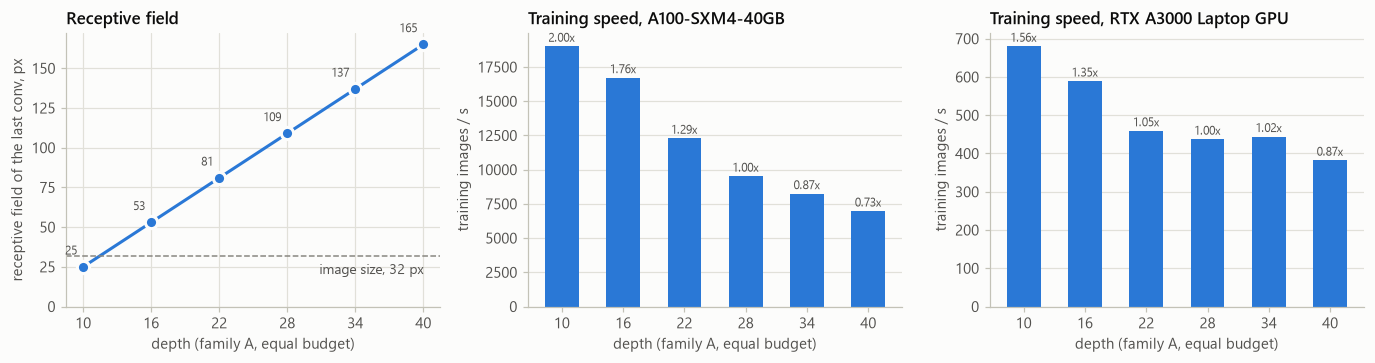

In [3]:
fam_a = shapes[shapes.family == "A"].sort_values("depth")
speed_cols = [c for c in shapes.columns if c.startswith("train img/s")]
fig, axes = plt.subplots(1, 1 + len(speed_cols), figsize=(4.2 * (1 + len(speed_cols)), 3.4))
axes = np.atleast_1d(axes)

ax = axes[0]
ax.plot(fam_a.depth, fam_a["receptive field (px)"], color=BLUE, marker="o", ms=8, mec=SURFACE, mew=2)
ax.axhline(32, color=MUTED, lw=1, ls="--")
ax.annotate("image size, 32 px", (fam_a.depth.max(), 32), xytext=(0, -12), textcoords="offset points",
            ha="right", fontsize=9, color=INK2)
for d, rf in zip(fam_a.depth, fam_a["receptive field (px)"]):
    ax.annotate(f"{rf}", (d, rf), xytext=(-4, 8), textcoords="offset points", ha="right", fontsize=8, color=INK2)
ax.set_xticks(fam_a.depth)
ax.set_xlabel("depth (family A, equal budget)")
ax.set_ylabel("receptive field of the last conv, px")
ax.set_ylim(0, None)
ax.set_title("Receptive field")

for ax, col in zip(axes[1:], speed_cols):
    base = fam_a.loc[fam_a.run == BASE, col].iloc[0]
    ax.bar(fam_a.depth.astype(str), fam_a[col], width=0.55, color=BLUE)
    for x, (v, d) in enumerate(zip(fam_a[col], fam_a.depth)):
        ax.annotate(f"{v / base:.2f}x", (x, v), xytext=(0, 3), textcoords="offset points", ha="center",
                    fontsize=8, color=INK2)
    ax.set_xlabel("depth (family A, equal budget)")
    ax.set_ylabel("training images / s")
    ax.set_title(f"Training speed, {col[len('train img/s ('):-1]}")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "dw_shapes.png")
plt.show()

## 2. What to expect

* **Width (Zagoruyko & Komodakis, 2016).** At equal parameters, wide-and-shallow residual networks matched or beat very
  deep thin ones on CIFAR and trained several times faster. Family A tests whether that still holds inside a 5M budget.
* **Too shallow.** WRN-10 has one block per stage and a receptive field below the image size, so it should lose
  accuracy despite being the fastest.
* **Too deep and thin.** WRN-40 has the narrowest layers (48 channels in the 32x32 stage), little capacity per layer,
  and the slowest training.
* **The middle (16-28) should be close.** Gaps of 0.1-0.2% are the size of seed-to-seed noise for this recipe, which is
  why family A has two seeds and section 4 uses a paired test.
* **Families B and C** show how accuracy grows with parameters: by widening at depth 28 (B) or deepening at width
  (64,128,224) (C). If both curves are still rising steeply at 5M, the budget is the bottleneck; if they flatten,
  the remaining gains must come from training (longer schedules, distillation), as the earlier experiments found.

## 3. Results

Validation accuracy of the EMA weights on the 5,000 held-out training images, without TTA and with `flip_shift` TTA.
`a0` (97.12 / 97.54) is the earlier screen of the WRN-28 shape with the same recipe: `dwA_d28_w64` should land close to it.

In [4]:
def load_run(name):
    d = Path("runs") / name
    out = {"run": name, "status": "not run"}
    if (d / "log.csv").exists():
        log = pd.read_csv(d / "log.csv")
        out.update(status=f"epoch {int(log.epoch.max())}", epochs_done=int(log.epoch.max()))
        if len(log) > 2:
            out["img/s (training)"] = float(log.img_per_s.iloc[1:].median())
    if (d / "summary.json").exists():
        s = json.load(open(d / "summary.json"))
        out.update(status="done", none=100 * s["val_acc_none"], flip_shift=100 * s["val_acc_flip_shift"],
                   hours=s.get("train_hours"))
    return out


res = runs.merge(pd.DataFrame([load_run(r) for r in runs.run]), on="run")
res["params"] = res.run.str.replace(r"_s\d+$", "", regex=True).map(shapes.set_index("run").params)
done = res[res.status == "done"]
print(f"{len(done)} of {len(res)} runs finished")
display(res.set_index("run")[["family", "seed", "depth", "widths", "status"] +
        [c for c in ("none", "flip_shift", "hours", "img/s (training)") if c in res]].round(2))

17 of 17 runs finished


,family,seed,depth,widths,status,none,flip_shift,hours,img/s (training)
run,,,,,,,,,
dwA_d10_w144,A,0,10,"(144, 288, 488)",done,95.74,96.10,0.21,12147.0
dwA_d16_w96,A,0,16,"(96, 192, 328)",done,96.78,97.44,0.26,9763.0
dwA_d22_w72,A,0,22,"(72, 144, 264)",done,97.04,97.56,0.32,7984.0
dwA_d28_w64,A,0,28,"(64, 128, 224)",done,96.88,97.60,0.34,7290.0
dwA_d34_w56,A,0,34,"(56, 112, 200)",done,97.16,97.48,0.39,6466.0
dwA_d40_w48,A,0,40,"(48, 96, 184)",done,96.84,97.12,0.46,5555.0
dwB_d28_w32,B,0,28,"(32, 64, 112)",done,95.84,96.30,0.34,7387.0
dwB_d28_w48,B,0,28,"(48, 96, 168)",done,96.78,97.22,0.36,7068.0
dwC_d10_w64,C,0,10,"(64, 128, 224)",done,94.04,94.64,0.22,11693.0


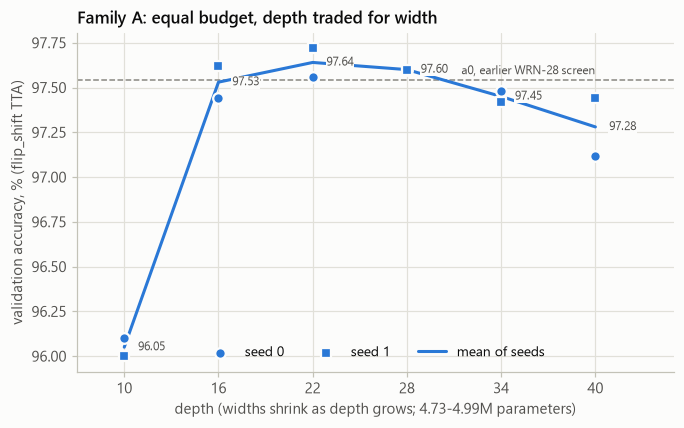

In [5]:
fa = done[done.family == "A"]
if fa.empty:
    print("no family-A results yet")
else:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.axhline(A0["flip_shift"], color=MUTED, lw=1, ls="--")
    ax.annotate("a0, earlier WRN-28 screen", (40, A0["flip_shift"]), xytext=(0, 4), textcoords="offset points",
                ha="right", fontsize=8, color=INK2)
    for seed, marker in ((0, "o"), (1, "s")):
        s = fa[fa.seed == seed]
        ax.scatter(s.depth, s.flip_shift, marker=marker, s=48, color=BLUE, edgecolor=SURFACE, linewidth=1.5,
                   zorder=3, label=f"seed {seed}")
    mean = fa.groupby("depth").flip_shift.mean()
    ax.plot(mean.index, mean.values, color=BLUE, lw=2, zorder=2, label="mean of seeds")
    for d, v in mean.items():
        ax.annotate(f"{v:.2f}", (d, v), xytext=(9, 0), textcoords="offset points", ha="left", va="center",
                    fontsize=8, color=INK2, bbox=dict(fc=SURFACE, ec="none", pad=0.6), zorder=4)
    ax.set_xticks(sorted(fa.depth.unique()))
    ax.set_xlim(fa.depth.min() - 3, fa.depth.max() + 5)
    ax.set_xlabel("depth (widths shrink as depth grows; 4.73-4.99M parameters)")
    ax.set_ylabel("validation accuracy, % (flip_shift TTA)")
    ax.legend(loc="lower center", ncol=3)
    ax.set_title("Family A: equal budget, depth traded for width")
    fig.savefig(FIG_DIR / "dw_family_a.png")
    plt.show()

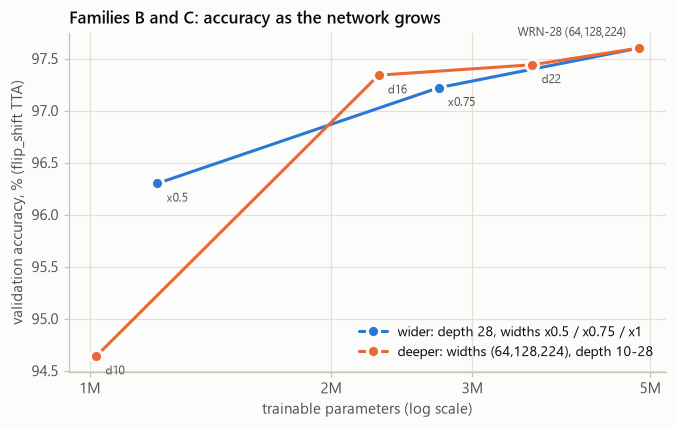

In [6]:
def curve(names):
    pts = done[done.run.isin(names)].sort_values("params")
    return pts.params / 1e6, pts.flip_shift, pts


wider = ["dwB_d28_w32", "dwB_d28_w48", BASE]
deeper = ["dwC_d10_w64", "dwC_d16_w64", "dwC_d22_w64", BASE]
if done[done.run.isin(wider + deeper)].empty:
    print("no family-B/C results yet")
else:
    fig, ax = plt.subplots(figsize=(7, 4))
    for names, color, label, tag in ((wider, BLUE, "wider: depth 28, widths x0.5 / x0.75 / x1", lambda r: f"x{r.widths[0] / 64:g}"),
                                     (deeper, ORANGE, "deeper: widths (64,128,224), depth 10-28", lambda r: f"d{r.depth}")):
        x, y, pts = curve(names)
        ax.plot(x, y, color=color, marker="o", ms=8, mec=SURFACE, mew=2, label=label)
        for r, xi, yi in zip(pts.itertuples(), x, y):
            if r.run != BASE:  # the shared end point is labelled once, below
                ax.annotate(tag(r), (xi, yi), xytext=(6, -12), textcoords="offset points", fontsize=8, color=INK2)
    if BASE in set(done.run):
        b = done[done.run == BASE].iloc[0]
        ax.annotate("WRN-28 (64,128,224)", (b.params / 1e6, b.flip_shift), xytext=(-8, 8), textcoords="offset points",
                    ha="right", fontsize=8, color=INK2)
    ax.set_xscale("log")
    ax.set_xticks([1, 2, 3, 5], ["1M", "2M", "3M", "5M"])
    ax.set_xticks([], minor=True)
    ax.set_xlabel("trainable parameters (log scale)")
    ax.set_ylabel("validation accuracy, % (flip_shift TTA)")
    ax.legend(loc="lower right")
    ax.set_title("Families B and C: accuracy as the network grows")
    fig.savefig(FIG_DIR / "dw_scaling.png")
    plt.show()

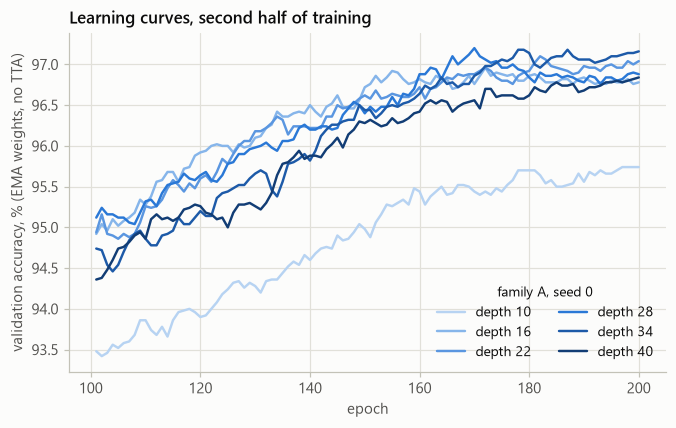

In [7]:
logs = {r: pd.read_csv(Path("runs") / r / "log.csv") for r in runs.run if (Path("runs") / r / "log.csv").exists()}
fam_a0 = [r for r in shapes[shapes.family == "A"].sort_values("depth").run if r in logs]
if not fam_a0:
    print("no family-A training logs yet")
else:
    fig, ax = plt.subplots(figsize=(7, 4))
    for r in fam_a0:
        d = int(shapes.loc[shapes.run == r, "depth"].iloc[0])
        color = DEPTH_RAMP[[10, 16, 22, 28, 34, 40].index(d)]
        log = logs[r]
        last = log[log.epoch > log.epoch.max() / 2]  # the second half, where the shapes separate
        ax.plot(last.epoch, 100 * last.val_acc_ema, color=color, lw=1.6, label=f"depth {d}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation accuracy, % (EMA weights, no TTA)")
    ax.legend(loc="lower right", ncol=2, title="family A, seed 0", title_fontsize=9)
    ax.set_title("Learning curves, second half of training")
    fig.savefig(FIG_DIR / "dw_curves.png")
    plt.show()

## 4. Is a difference real? Paired test against WRN-28

Two models evaluated on the same 5,000 images can be compared image by image: what matters is how many images only one
of them gets right (McNemar's exact test). This is far more sensitive than comparing two accuracies, and it is the
test the earlier experiments used (`scripts/compare_runs.py`). Predictions are the saved `val_probs.npy`
(flip TTA). Each shape is compared with WRN-28 of the same seed; "pooled" adds both seeds' images together.

**Decision rule for stage 2** (`queues/hpc_depth_width_stage2.txt`): a shape qualifies only if it beats WRN-28 by at
least 0.3 points on both seeds and the pooled test gives p < 0.05.

In [8]:
from resnet5m.data import load_cifar10_train, stratified_split


def mcnemar_p(b, c):
    # exact two-sided binomial test on the discordant pairs
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    return min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) / 2 ** n)


_, y_all = load_cifar10_train("data")
_, val_idx = stratified_split(y_all, 5000, 0)
y_val = y_all[val_idx]


def correct(run):
    p = Path("runs") / run / "val_probs.npy"
    return np.load(p).astype(np.float32).argmax(1) == y_val if p.exists() else None


rows = []
for shape in shapes[(shapes.family == "A") & (shapes.run != BASE)].sort_values("depth").run:
    row, b_all, c_all, deltas = {"shape": shape}, 0, 0, []
    for seed, suffix in ((0, ""), (1, "_s1")):
        a, base = correct(shape + suffix), correct(BASE + suffix)
        if a is None or base is None:
            continue
        b, c = int((a & ~base).sum()), int((~a & base).sum())
        delta = 100 * (a.mean() - base.mean())
        row.update({f"seed {seed}: Δ pts": round(delta, 2), f"seed {seed}: only shape / only WRN-28": f"{b} / {c}",
                    f"seed {seed}: p": round(mcnemar_p(b, c), 3)})
        b_all, c_all = b_all + b, c_all + c
        deltas.append(delta)
    if deltas:
        row["pooled p"] = round(mcnemar_p(b_all, c_all), 3)
        row["qualifies"] = len(deltas) == 2 and min(deltas) >= 0.3 and row["pooled p"] < 0.05
        rows.append(row)
if rows:
    table = pd.DataFrame(rows).set_index("shape")
    display(table)
    winners = table.index[table.qualifies].tolist()
    print("stage-2 candidates:", winners or "none: keep WRN-28 (64,128,224)")
else:
    print("no paired results yet (needs val_probs.npy of a family-A shape and of dwA_d28_w64 with the same seed)")

,seed 0: Δ pts,seed 0: only shape / only WRN-28,seed 0: p,seed 1: Δ pts,seed 1: only shape / only WRN-28,seed 1: p,pooled p,qualifies
shape,,,,,,,,
dwA_d10_w144,-1.54,50 / 127,0.000,-1.84,45 / 137,0.000,0.000,False
dwA_d16_w96,-0.16,46 / 54,0.484,-0.04,52 / 54,0.923,0.531,False
dwA_d22_w72,0.14,53 / 46,0.547,0.20,42 / 32,0.295,0.224,False
dwA_d34_w56,0.30,51 / 36,0.133,-0.06,38 / 41,0.822,0.393,False
dwA_d40_w48,-0.40,39 / 59,0.054,0.00,50 / 50,1.000,0.177,False


stage-2 candidates: none: keep WRN-28 (64,128,224)


## 5. Accuracy against training speed

At equal accuracy the faster shape is the better choice, because the earlier experiments found longer training to be
the strongest lever: a 1.3x faster shape gets 1.3x the epochs in the same GPU-hours. The x axis is the training
throughput the cluster measured (median images per second over the run, from `log.csv`).

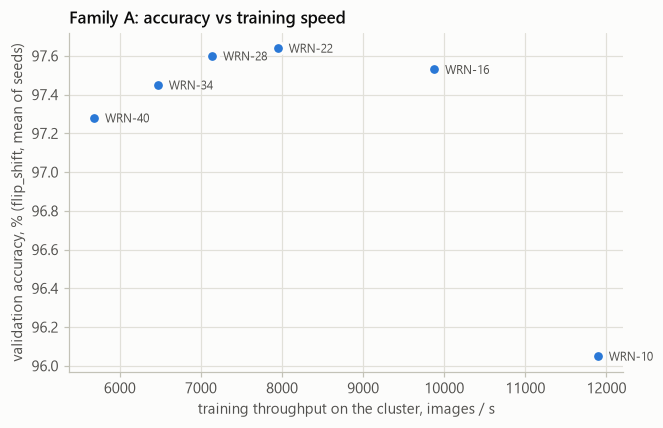

In [9]:
fa = done[(done.family == "A") & done["img/s (training)"].notna()] if "img/s (training)" in done else done.iloc[:0]
if fa.empty:
    print("no family-A results with throughput yet")
else:
    g = fa.groupby("depth").agg(acc=("flip_shift", "mean"), speed=("img/s (training)", "mean"))
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.scatter(g.speed, g.acc, s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    for d, r in g.iterrows():
        ax.annotate(f"WRN-{d}", (r.speed, r.acc), xytext=(7, -3), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_xlabel("training throughput on the cluster, images / s")
    ax.set_ylabel("validation accuracy, % (flip_shift, mean of seeds)")
    ax.set_title("Family A: accuracy vs training speed")
    fig.savefig(FIG_DIR / "dw_speed_accuracy.png")
    plt.show()

## Notes for the report

* Fill in after the runs return: which shape won (or that the middle depths tie), the size of the gaps relative to
  seed noise, how accuracy scales in families B and C, and the speed ranking.
* Every model here is under the 5,000,000-parameter limit (asserted in section 1 and again by `train.py`).
* These are 200-epoch screens with a plain recipe: a ranking here is evidence about the architecture, not a final
  accuracy. A shape that qualifies in section 4 is retrained with the final model's distillation recipe
  (`queues/hpc_depth_width_stage2.txt`) before it can replace WRN-28.